In [1]:
import pandas as pd
import numpy as np
import re
import optuna
from optuna.samplers import TPESampler
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

c:\dev\ADIA-Lab-Structural-Break-Open-Benchmark-Challenge-Project\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# ==============================================================================
# 1. LOAD DATASET
# ==============================================================================
print("Loading Purified Dataset (Top 75)...")

X_purified = pd.read_parquet('../data/processed/features_top75.parquet')
y_train = pd.read_parquet('../data/raw/y_train.parquet')
y = y_train.loc[X_purified.index]['structural_breakpoint']

print(f"Features shape: {X_purified.shape}")

imbalance_ratio = float((y == 0).sum() / (y == 1).sum())
print(f"Class imbalance ratio: {imbalance_ratio:.4f}")

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

Loading Purified Dataset (Top 75)...
Features shape: (10001, 75)
Class imbalance ratio: 2.4380


In [3]:
# ==============================================================================
# 2. PHASE 1: OPTIMIZING XGBOOST
# ==============================================================================
print("\n" + "="*60)
print("PHASE 1: TUNING XGBOOST WITH OPTUNA")
print("="*60)

def objective_xgb(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 200, 500, step=50),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 8),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 10),
        'gamma': trial.suggest_float('gamma', 0.0, 0.5),
        'scale_pos_weight': imbalance_ratio,
        'eval_metric': 'auc',
        'random_state': 42,
        'n_jobs': -1
    }
    
    model = xgb.XGBClassifier(**params)
    scores = cross_val_score(model, X_purified, y, cv=cv_strategy, scoring='roc_auc', n_jobs=1)
    return np.mean(scores)

sampler_xgb = TPESampler(seed=42)
study_xgb = optuna.create_study(direction='maximize', study_name="XGB_Top75", sampler=sampler_xgb)
study_xgb.optimize(objective_xgb, n_trials=50, show_progress_bar=True)

print(f"Best XGBoost ROC AUC: {study_xgb.best_value:.4f}")
print(f"Best XGBoost parameters: {study_xgb.best_params}")


PHASE 1: TUNING XGBOOST WITH OPTUNA


Best trial: 10. Best value: 0.791853: 100%|██████████| 50/50 [07:56<00:00,  9.54s/it]

Best XGBoost ROC AUC: 0.7919
Best XGBoost parameters: {'n_estimators': 350, 'learning_rate': 0.05083158501542684, 'max_depth': 8, 'subsample': 0.9729161367647149, 'colsample_bytree': 0.6061470949312417, 'min_child_weight': 5, 'gamma': 0.007572118551378439}


In [4]:
# ==============================================================================
# 3. PHASE 2: OPTIMIZING LIGHTGBM
# ==============================================================================
print("\n" + "="*60)
print("PHASE 2: TUNING LIGHTGBM WITH OPTUNA")
print("="*60)

def objective_lgb(trial):
    max_depth = trial.suggest_int('max_depth', 3, 8)
    max_leaves_allowed = min(256, 2**max_depth)
    
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 200, 500, step=50),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'max_depth': max_depth,
        'num_leaves': trial.suggest_int('num_leaves', min(4, max_leaves_allowed), max_leaves_allowed),
        'min_child_samples': trial.suggest_int('min_child_samples', 10, 100),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'scale_pos_weight': imbalance_ratio,
        'random_state': 42,
        'n_jobs': -1,
        'verbose': -1
    }
    
    model = lgb.LGBMClassifier(**params)
    scores = cross_val_score(model, X_purified, y, cv=cv_strategy, scoring='roc_auc', n_jobs=1)
    return np.mean(scores)

sampler_lgb = TPESampler(seed=42)
study_lgb = optuna.create_study(direction='maximize', study_name="LGBM_Top75", sampler=sampler_lgb)
study_lgb.optimize(objective_lgb, n_trials=50, show_progress_bar=True)

print(f"Best LightGBM ROC AUC: {study_lgb.best_value:.4f}")
print(f"Best LightGBM parameters: {study_lgb.best_params}")


PHASE 2: TUNING LIGHTGBM WITH OPTUNA


Best trial: 32. Best value: 0.788962: 100%|██████████| 50/50 [02:06<00:00,  2.52s/it]

Best LightGBM ROC AUC: 0.7890
Best LightGBM parameters: {'max_depth': 8, 'n_estimators': 350, 'learning_rate': 0.03163661347608696, 'num_leaves': 169, 'min_child_samples': 58, 'subsample': 0.9156545808727808, 'colsample_bytree': 0.7755355038366832}


In [5]:
# ==============================================================================
# 4. PHASE 3: THE ULTIMATE ENSEMBLE
# ==============================================================================
print("\n" + "="*60)
print("PHASE 3: EVALUATING THE ULTIMATE TUNED ENSEMBLE")
print("Target to beat: 0.7933 (Un-tuned Top 75 Ensemble)")
print("="*60)

best_xgb_params = study_xgb.best_params
best_xgb_params.update({'scale_pos_weight': imbalance_ratio, 'eval_metric': 'auc', 'random_state': 42, 'n_jobs': -1})
final_xgb = xgb.XGBClassifier(**best_xgb_params)

best_lgb_params = study_lgb.best_params
best_lgb_params.update({'scale_pos_weight': imbalance_ratio, 'random_state': 42, 'n_jobs': -1, 'verbose': -1})
final_lgb = lgb.LGBMClassifier(**best_lgb_params)

# CatBoost with strong defaults
final_cat = CatBoostClassifier(
    iterations=400, learning_rate=0.05, depth=6,
    scale_pos_weight=imbalance_ratio, eval_metric='AUC',
    random_state=42, verbose=0, thread_count=-1
)

final_ensemble = VotingClassifier(
    estimators=[('xgb', final_xgb), ('lgb', final_lgb), ('cat', final_cat)],
    voting='soft', n_jobs=1
)

final_scores = cross_val_score(final_ensemble, X_purified, y, cv=cv_strategy, scoring='roc_auc', n_jobs=1)
mean_final_auc = np.mean(final_scores)

print(f"\nTHE ULTIMATE ENSEMBLE ROC AUC: {mean_final_auc:.4f}")


PHASE 3: EVALUATING THE ULTIMATE TUNED ENSEMBLE
Target to beat: 0.7933 (Un-tuned Top 75 Ensemble)

THE ULTIMATE ENSEMBLE ROC AUC: 0.7960


Generating out-of-fold predictions for Confusion Matrix...


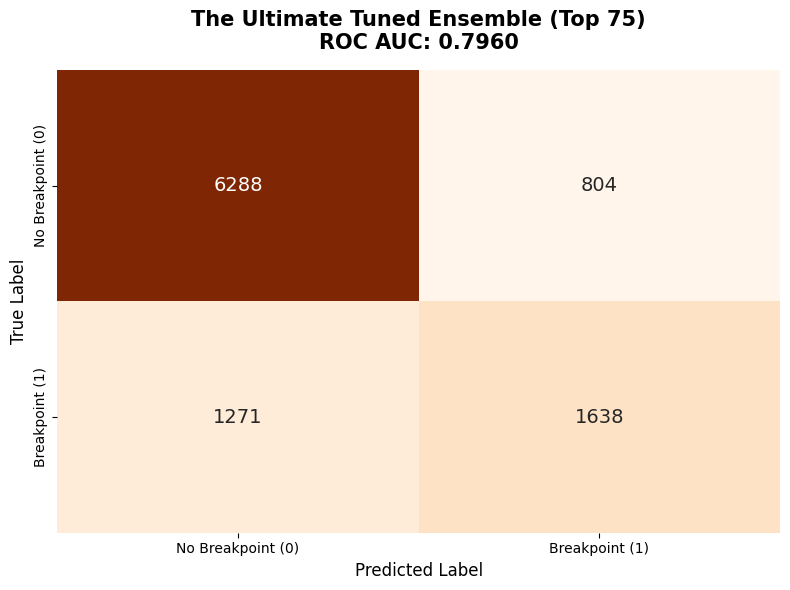


FINAL CLASSIFICATION REPORT:
              precision    recall  f1-score   support

       False     0.8319    0.8866    0.8584      7092
        True     0.6708    0.5631    0.6122      2909

    accuracy                         0.7925     10001
   macro avg     0.7513    0.7249    0.7353     10001
weighted avg     0.7850    0.7925    0.7868     10001



In [6]:
# ==============================================================================
# 5. VISUALIZATION OF THE ULTIMATE CONFUSION MATRIX
# ==============================================================================
print("Generating out-of-fold predictions for Confusion Matrix...")
y_pred_proba = cross_val_predict(final_ensemble, X_purified, y, cv=cv_strategy, method='predict_proba', n_jobs=1)[:, 1]
y_pred_bin = (y_pred_proba >= 0.5).astype(int)

cm = confusion_matrix(y, y_pred_bin)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', cbar=False,
            xticklabels=['No Breakpoint (0)', 'Breakpoint (1)'],
            yticklabels=['No Breakpoint (0)', 'Breakpoint (1)'],
            annot_kws={"size": 14})

plt.title(f'The Ultimate Tuned Ensemble (Top 75)\nROC AUC: {mean_final_auc:.4f}', 
          fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.tight_layout()
plt.show()

print("\nFINAL CLASSIFICATION REPORT:")
print(classification_report(y, y_pred_bin, digits=4))